# AE-RL for ACI-IoT-2023

This notebook adapts the original AE-RL (Adversarial Environment + Reinforcement Learning) setup from NSL-KDD to a more recent IDS dataset (default: **ACI-IoT-2023**).

**Key changes vs. the original notebook**
- Dataset: ACI-IoT-2023 (optionally extendable to other tabular IDS datasets).
- Asymmetric agents: **Attacker = DQN** (RL), **Defender = DNN** (supervised classifier).
- Defender explainability: **SHAP** (and optional **SAGE**) feature attributions.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from keras.models import Sequential
from keras.layers import Dense
from keras import optimizers
from keras import backend as K
import json
from sklearn.utils import shuffle
import os
import sys
import time

In [2]:
# Optional: install explainability libraries (run if needed)
# !pip -q install shap sage-importance

import warnings
warnings.filterwarnings('ignore')


In [3]:
# ----------------------------
# Dataset wrapper (ACI-IoT-2023)
# ----------------------------
# Expected raw data: either a single CSV file OR a folder of CSVs.
# ACI-IoT-2023 label classes commonly include: Benign, Port Scan, ICMP Flood, Ping Sweep, DNS Flood,
# Vulnerability Scan, OS Scan, Slowloris, SYN Flood, Dictionary Attack, UDP Flood, ARP Spoofing.
#
# Notes:
# - Drops obvious identifier columns (Flow ID, IPs, Timestamp, MACs, etc.).
# - Low-cardinality categorical columns are one-hot encoded; high-cardinality ones are dropped.
# - Produces a formatted CSV with [scaled features] + [one-hot fine labels].

import os
import json
from glob import glob

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils import shuffle


def _label_to_type(label: str) -> str:
    """Map ACI-IoT-2023 fine label -> coarse defender label."""
    s = str(label).strip().lower()

    if s in {"benign", "normal", "0"} or "benign" in s:
        return "BENIGN"
    if "dictionary" in s or "brute" in s:
        return "BruteForce"
    if "arp" in s or "spoof" in s:
        return "Spoofing"
    if "scan" in s or "sweep" in s or "recon" in s:
        return "Recon"
    if "flood" in s or "slowloris" in s or "syn" in s or "udp" in s or "icmp" in s or "dns" in s:
        return "DoS"
    return "OtherAttack"


def _looks_like_id_column(col: str) -> bool:
    c = str(col).strip().lower()
    return any(k in c for k in [
        "flow id", "timestamp", "src ip", "dst ip", "source ip", "destination ip",
        "src mac", "dst mac", "frame src", "frame dst",
        "uid", "session", "uuid"
    ])

def _pick_label_column(df: pd.DataFrame, preferred: str = "Label") -> str:
    if preferred in df.columns:
        return preferred
    low = {c.lower(): c for c in df.columns}
    for cand in ["label", "class", "attack", "category", "target", "type"]:
        if cand in low:
            return low[cand]
    raise ValueError("Could not find a label column. Tried: Label, label/class/attack/category/target/type")

def _encode_features(df: pd.DataFrame, drop_cols, max_cardinality: int = 50) -> pd.DataFrame:
    X = df.drop(columns=list(drop_cols), errors="ignore").copy()

    # Drop identifier-like columns
    id_cols = [c for c in X.columns if _looks_like_id_column(c)]
    if len(id_cols) > 0:
        X.drop(columns=id_cols, inplace=True, errors="ignore")

    # Split categorical vs numeric
    obj_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()

    # Keep low-card categorical columns; drop high-card (IPs, hashes, etc.)
    low_card = [c for c in obj_cols if X[c].nunique(dropna=True) <= max_cardinality]
    high_card = [c for c in obj_cols if c not in low_card]
    if len(high_card) > 0:
        X.drop(columns=high_card, inplace=True, errors="ignore")

    if len(low_card) > 0:
        X = pd.get_dummies(X, columns=low_card, dummy_na=True)

    # Convert to numeric + clean
    X = X.apply(pd.to_numeric, errors="coerce")
    X.replace([np.inf, -np.inf], np.nan, inplace=True)
    X.fillna(0.0, inplace=True)

    # Drop constant columns
    nunq = X.nunique(dropna=False)
    const_cols = nunq[nunq <= 1].index.tolist()
    if len(const_cols) > 0:
        X.drop(columns=const_cols, inplace=True, errors="ignore")

    return X

class data_cls:
    def __init__(self, train_test, **kwargs):
        self.train_test = train_test
        self.dataset = kwargs.get("dataset", "ACI-IoT-2023")

        # Paths
        self.data_dir = kwargs.get("data_dir", r"C:/Users/Curtis Rookard/OneDrive/Desktop/Research/Research Projects/Asymmetric_RL_Agents/datasets/aci/")
        self.formated_train_path = kwargs.get("formated_train_path", "formated_train_aci_iot_2023_adv.csv")
        self.formated_test_path  = kwargs.get("formated_test_path",  "formated_test_aci_iot_2023_adv.csv")

        # Options
        self.test_size = kwargs.get("test_size", 0.2)
        self.random_state = kwargs.get("random_state", 42)
        self.force_reformat = kwargs.get("force_reformat", False)
        self.include_benign = kwargs.get("include_benign", True)

        # Populated after formatting/loading
        self.attack_names = []
        self.all_attack_names = []
        self.attack_types = []
        self.attack_map = {}

    def _meta_path(self, formatted_path: str) -> str:
        return formatted_path + ".meta.json"

    def _try_load_meta(self, formatted_path: str) -> bool:
        meta_p = self._meta_path(formatted_path)
        if os.path.exists(meta_p):
            with open(meta_p, "r", encoding="utf-8") as f:
                meta = json.load(f)
            self.all_attack_names = meta["all_attack_names"]
            self.attack_names = meta["attack_names"]
            self.attack_types = meta["attack_types"]
            self.attack_map = meta["attack_map"]
            return True
        return False

    def _save_meta(self, formatted_path: str):
        meta = {
            "dataset": self.dataset,
            "all_attack_names": self.all_attack_names,
            "attack_names": self.attack_names,
            "attack_types": self.attack_types,
            "attack_map": self.attack_map,
        }
        with open(self._meta_path(formatted_path), "w", encoding="utf-8") as f:
            json.dump(meta, f, indent=2)

    def _load_raw(self) -> pd.DataFrame:
        # data_dir can be a directory OR a single CSV file path
        if os.path.isfile(self.data_dir) and self.data_dir.lower().endswith(".csv"):
            csv_files = [self.data_dir]
        else:
            csv_files = sorted(glob(os.path.join(self.data_dir, "**", "*.csv"), recursive=True))

        if len(csv_files) == 0:
            raise FileNotFoundError(
                "No CSVs found at data_dir='" + str(self.data_dir) + "'.\n"
                "Fix: set data_dir to a CSV file path or a folder that contains CSVs."
            )

        dfs = []
        for fp in csv_files:
            try:
                dfs.append(pd.read_csv(fp, low_memory=False))
            except Exception as e:
                print("[WARN] Skipping unreadable CSV:", fp, "(", e, ")")

        if len(dfs) == 0:
            raise FileNotFoundError("No readable CSVs were found.")

        return pd.concat(dfs, ignore_index=True)

    def _ensure_formatted(self):
        train_ok = os.path.exists(self.formated_train_path)
        test_ok  = os.path.exists(self.formated_test_path)

        if (not self.force_reformat) and train_ok and test_ok:
            if self._try_load_meta(self.formated_train_path):
                return

        df = self._load_raw()
        label_col = _pick_label_column(df, preferred="Label")

        y_fine = df[label_col].astype(str).str.strip()
        y_coarse = y_fine.map(_label_to_type)

        if not self.include_benign:
            keep = y_coarse != "BENIGN"
            df = df.loc[keep].reset_index(drop=True)
            y_fine = y_fine.loc[keep].reset_index(drop=True)

        X = _encode_features(df, drop_cols=[label_col])
        fine_labels = sorted(y_fine.unique().tolist())

        attack_map = {lbl: _label_to_type(lbl) for lbl in fine_labels}
        attack_types = []
        for lbl in fine_labels:
            t = attack_map[lbl]
            if t not in attack_types:
                attack_types.append(t)

        strat = y_fine if y_fine.nunique() > 1 else None
        X_train, X_test, y_train, y_test = train_test_split(
            X, y_fine, test_size=self.test_size, random_state=self.random_state, stratify=strat
        )

        scaler = StandardScaler()
        X_train_s = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
        X_test_s  = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

        y_train_oh = pd.get_dummies(y_train, prefix="", prefix_sep="").reindex(columns=fine_labels, fill_value=0)
        y_test_oh  = pd.get_dummies(y_test,  prefix="", prefix_sep="").reindex(columns=fine_labels, fill_value=0)

        train_df = pd.concat([X_train_s.reset_index(drop=True), y_train_oh.reset_index(drop=True)], axis=1)
        test_df  = pd.concat([X_test_s.reset_index(drop=True),  y_test_oh.reset_index(drop=True)], axis=1)

        train_df.to_csv(self.formated_train_path, index=False)
        test_df.to_csv(self.formated_test_path, index=False)

        self.all_attack_names = fine_labels
        self.attack_names = fine_labels
        self.attack_types = attack_types
        self.attack_map = attack_map
        self._save_meta(self.formated_train_path)
        self._save_meta(self.formated_test_path)

    def _load_df(self):
        self._ensure_formatted()

        path = self.formated_train_path if self.train_test == "train" else self.formated_test_path
        self.df = pd.read_csv(path, low_memory=False)

        label_cols = [c for c in self.df.columns if c in self.all_attack_names]
        if len(label_cols) == 0:
            raise ValueError("Formatted file has no one-hot label columns. Re-run with force_reformat=True.")

        label_sums = self.df[label_cols].sum(axis=0)
        self.attack_names = [c for c in label_cols if label_sums.get(c, 0) > 0]

        self.df = shuffle(self.df, random_state=self.random_state).reset_index(drop=True)

    def get_shape(self):
        return self.df.shape

    def get_batch(self, batch_size=1):
        if batch_size == "full":
            batch_size = len(self.df)

        batch = self.df.sample(int(batch_size))
        labels = batch[self.attack_names]
        batch = batch.drop(columns=self.all_attack_names, errors="ignore")
        return batch, labels


In [4]:
# Huber loss function        
def huber_loss(y_true, y_pred, clip_value=1):
    # Huber loss, see https://en.wikipedia.org/wiki/Huber_loss and
    # https://medium.com/@karpathy/yes-you-should-understand-backprop-e2f06eab496b
    # for details.
    assert clip_value > 0.

    x = y_true - y_pred
    if np.isinf(clip_value):
        # Spacial case for infinity since Tensorflow does have problems
        # if we compare `K.abs(x) < np.inf`.
        return .5 * K.square(x)

    condition = K.abs(x) < clip_value
    squared_loss = .5 * K.square(x)
    linear_loss = clip_value * (K.abs(x) - .5 * clip_value)
    if K.backend() == 'tensorflow':
        import tensorflow as tf
        if hasattr(tf, 'select'):
            return tf.select(condition, squared_loss, linear_loss)  # condition, true, false
        else:
            return tf.where(condition, squared_loss, linear_loss)  # condition, true, false
    elif K.backend() == 'theano':
        from theano import tensor as T
        return T.switch(condition, squared_loss, linear_loss)
    else:
        raise RuntimeError('Unknown backend "{}".'.format(K.backend()))

# Needed for keras huber_loss locate
import keras.losses
keras.losses.huber_loss = huber_loss


In [5]:
class QNetwork():
    """
    Q-Network Estimator
    Represents the global model for the table
    """

    def __init__(self,obs_size,num_actions,hidden_size = 100,
                 hidden_layers = 1,learning_rate=.2):
        """
        Initialize the network with the provided shape
        """
        self.obs_size = obs_size
        self.num_actions = num_actions
        
        # Network arquitecture
        self.model = Sequential()
        # Add imput layer
        self.model.add(Dense(hidden_size, input_shape=(obs_size,),
                             activation='relu'))
        # Add hidden layers
        for layers in range(hidden_layers):
            self.model.add(Dense(hidden_size, activation='relu'))
        # Add output layer    
        self.model.add(Dense(num_actions))
        
        #optimizer = optimizers.SGD(learning_rate)
        # optimizer = optimizers.Adam(alpha=learning_rate)
        optimizer = optimizers.Adam(0.00025)
        # optimizer = optimizers.RMSpropGraves(learning_rate, 0.95, self.momentum, 1e-2)
        
        self.model.compile(
            optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
            loss=keras.losses.Huber(delta=1),
        )

    def predict(self,state,batch_size=1):
        """
        Predicts action values.
        """
        return self.model.predict(state,batch_size=batch_size)

    def update(self, states, q):
        """
        Updates the estimator with the targets.

        Args:
          states: Target states
          q: Estimated values

        Returns:
          The calculated loss on the batch.
        """
        loss = self.model.train_on_batch(states, q)
        return loss
    
    def copy_model(model):
        """Returns a copy of a keras model."""
        model.save('tmp_model.keras')
        return keras.models.load_model('tmp_model.keras', custom_objects={"huber_loss": huber_loss})


In [6]:
#Policy interface
class Policy:
    def __init__(self, num_actions, estimator):
        self.num_actions = num_actions
        self.estimator = estimator
    
class Epsilon_greedy(Policy):
    def __init__(self,estimator ,num_actions ,epsilon,min_epsilon,decay_rate, epoch_length):
        Policy.__init__(self, num_actions, estimator)
        self.name = "Epsilon Greedy"
        
        if (epsilon is None or epsilon < 0 or epsilon > 1):
            print("EpsilonGreedy: Invalid value of epsilon", flush = True)
            sys.exit(0)
        self.epsilon = epsilon
        self.min_epsilon = min_epsilon
        self.actions = list(range(num_actions))
        self.step_counter = 0
        self.epoch_length = epoch_length
        self.decay_rate = decay_rate
        
        #if epsilon is up 0.1, it will be decayed over time
        if self.epsilon > 0.01:
            self.epsilon_decay = True
        else:
            self.epsilon_decay = False
    
    def get_actions(self,states):
        # get next action
        if np.random.rand() <= self.epsilon:
            actions = np.random.randint(0, self.num_actions,states.shape[0])
        else:
            self.Q = self.estimator.predict(states,states.shape[0])
            actions = []
            for row in range(self.Q.shape[0]):
                best_actions = np.argwhere(self.Q[row] == np.amax(self.Q[row]))
                actions.append(best_actions[np.random.choice(len(best_actions))].item())
            
        self.step_counter += 1 
        # decay epsilon after each epoch
        if self.epsilon_decay:
            if self.step_counter % self.epoch_length == 0:
                self.epsilon = max(self.min_epsilon, self.epsilon * self.decay_rate**self.step_counter)
            
        return actions

In [7]:
# class ReplayMemory(object):
#     """Implements basic replay memory"""

#     def __init__(self, observation_size, max_size):
#         self.observation_size = observation_size
#         self.num_observed = 0
#         self.max_size = max_size
#         self.samples = {
#                  'obs'      : np.zeros(self.max_size * 1 * self.observation_size,
#                                        dtype=np.float32).reshape(self.max_size,self.observation_size),
#                  'action'   : np.zeros(self.max_size * 1, dtype=np.int16).reshape(self.max_size, 1),
#                  'reward'   : np.zeros(self.max_size * 1).reshape(self.max_size, 1),
#                  'terminal' : np.zeros(self.max_size * 1, dtype=np.int16).reshape(self.max_size, 1),
#                }

#     # def observe(self, state, action, reward, done):
#     #     index = self.num_observed % self.max_size
#     #     self.samples['obs'][index, :] = state
#     #     self.samples['action'][index, :] = action
#     #     self.samples['reward'][index, :] = reward
#     #     self.samples['terminal'][index, :] = done

#     #     self.num_observed += 1

#     def observe(self, state, action, reward, done):
#             # Convert DataFrame -> ndarray
#         if isinstance(state, pd.DataFrame):
#             state = state.to_numpy()
    
#         state = np.asarray(state)
#         action = np.asarray(action)
    
#         # If batch of states, insert each transition
#         if state.ndim == 2:
#             n = state.shape[0]
    
#             # Make reward/done arrays length n
#             if np.isscalar(reward):
#                 reward = np.full((n,), reward, dtype=np.float32)
#             else:
#                 reward = np.asarray(reward).reshape(-1)
    
#             if np.isscalar(done):
#                 done = np.full((n,), done, dtype=np.float32)
#             else:
#                 done = np.asarray(done).reshape(-1)
    
#             # Make action length n (if scalar, repeat; if already length n, keep)
#             if action.ndim == 0:
#                 action = np.full((n,), action, dtype=np.int64)
#             else:
#                 action = action.reshape(-1)
    
#             # Push each row
#             for s, a, r, d in zip(state, action, reward, done):
#                 self.observe(s, a, r, d)
#             return
    
#     def sample_minibatch(self, minibatch_size):
#         max_index = min(self.num_observed, self.max_size) - 1
#         if max_index <= 0:
#             raise ValueError(f"Not enough samples to draw minibatch yet. num_observed={self.num_observed}")
    
#         sampled_indices = np.random.randint(0, max_index, size=minibatch_size)

#         s      = np.asarray(self.samples['obs'][sampled_indices, :], dtype=np.float32)
#         s_next = np.asarray(self.samples['obs'][sampled_indices+1, :], dtype=np.float32)

#         a      = self.samples['action'][sampled_indices].reshape(minibatch_size)
#         r      = self.samples['reward'][sampled_indices].reshape((minibatch_size, 1))
#         done   = self.samples['terminal'][sampled_indices].reshape((minibatch_size, 1))

#         return (s, a, r, s_next, done)

In [8]:
class ReplayMemory(object):
    """Replay memory storing full transitions: (s, a, r, s', done)."""

    def __init__(self, observation_size, max_size):
        self.observation_size = int(observation_size)
        self.max_size = int(max_size)
        self.num_observed = 0

        self.samples = {
            "obs":      np.zeros((self.max_size, self.observation_size), dtype=np.float32),
            "next_obs": np.zeros((self.max_size, self.observation_size), dtype=np.float32),
            "action":   np.zeros((self.max_size, 1), dtype=np.int16),
            "reward":   np.zeros((self.max_size, 1), dtype=np.float32),
            "terminal": np.zeros((self.max_size, 1), dtype=np.int16),
        }

    def _to_2d_state(self, x):
        # DataFrame -> ndarray
        if isinstance(x, pd.DataFrame):
            x = x.to_numpy()
        x = np.asarray(x, dtype=np.float32)
        if x.ndim == 1:
            x = x.reshape(1, -1)
        return x

    def _to_1d(self, x):
        x = np.asarray(x)
        if x.ndim == 0:
            return x.reshape(1)
        return x.reshape(-1)

    def observe(self, state, action, reward, next_state, done):
        """
        Accepts single OR batched transitions.
        state / next_state can be (obs,), (N, obs) or pd.DataFrame.
        action can be scalar or (N,)
        reward can be scalar or (N,) or (N,1)
        done can be scalar or (N,) or (N,1)
        """
        s  = self._to_2d_state(state)
        ns = self._to_2d_state(next_state)

        if s.shape[1] != self.observation_size or ns.shape[1] != self.observation_size:
            raise ValueError(
                f"obs_size mismatch: expected {self.observation_size}, got {s.shape[1]} and {ns.shape[1]}"
            )

        n = s.shape[0]

        a = self._to_1d(action)
        r = self._to_1d(reward)
        d = self._to_1d(done)

        # Broadcast scalars / singletons to batch length n if needed
        if a.size == 1 and n > 1:
            a = np.full((n,), int(a[0]), dtype=np.int64)
        if r.size == 1 and n > 1:
            r = np.full((n,), float(r[0]), dtype=np.float32)
        if d.size == 1 and n > 1:
            d = np.full((n,), int(d[0]), dtype=np.int64)

        # Final sanity check
        if a.shape[0] != n or r.shape[0] != n or d.shape[0] != n:
            raise ValueError(f"Batch length mismatch: n={n}, action={a.shape}, reward={r.shape}, done={d.shape}")

        # Insert each row as its own transition
        for i in range(n):
            idx = self.num_observed % self.max_size
            self.samples["obs"][idx, :]      = s[i]
            self.samples["next_obs"][idx, :] = ns[i]
            self.samples["action"][idx, 0]   = int(a[i])
            self.samples["reward"][idx, 0]   = float(r[i])
            self.samples["terminal"][idx, 0] = int(d[i])
            self.num_observed += 1

    def sample_minibatch(self, minibatch_size):
        available = min(self.num_observed, self.max_size)
        if available < minibatch_size:
            raise ValueError(
                f"Not enough samples to draw minibatch yet. "
                f"num_observed={self.num_observed}, available={available}, minibatch_size={minibatch_size}"
            )

        sampled_indices = np.random.randint(0, available, size=minibatch_size)

        s      = self.samples["obs"][sampled_indices, :].astype(np.float32)
        s_next = self.samples["next_obs"][sampled_indices, :].astype(np.float32)

        a    = self.samples["action"][sampled_indices].reshape(minibatch_size)          # (mb,)
        r    = self.samples["reward"][sampled_indices].reshape((minibatch_size, 1))     # (mb,1)
        done = self.samples["terminal"][sampled_indices].reshape((minibatch_size, 1))   # (mb,1)

        return (s, a, r, s_next, done)

In [9]:
'''
Reinforcement learning Agent definition
'''

class Agent(object):  
        
    def __init__(self, actions,obs_size, policy="EpsilonGreedy", **kwargs):
        self.actions = actions
        self.num_actions = len(actions)
        self.obs_size = obs_size
        
        self.epsilon = kwargs.get('epsilon', 1)
        self.min_epsilon = kwargs.get('min_epsilon', .1)
        self.gamma = kwargs.get('gamma', .001)
        self.minibatch_size = kwargs.get('minibatch_size', 2)
        self.epoch_length = kwargs.get('epoch_length', 100)
        self.decay_rate = kwargs.get('decay_rate',0.99)
        self.ExpRep = kwargs.get('ExpRep',True)
        if self.ExpRep:
            self.memory = ReplayMemory(self.obs_size, kwargs.get('mem_size', 10))
            #self.memory = ReplayMemory(self.mem_size, self.obs_size)
        
        self.ddqn_time = 100
        self.ddqn_update = self.ddqn_time

        
        self.model_network = QNetwork(self.obs_size, self.num_actions,
                                      kwargs.get('hidden_size', 100),
                                      kwargs.get('hidden_layers',1),
                                      kwargs.get('learning_rate',.2))
        self.target_model_network = QNetwork(self.obs_size, self.num_actions,
                                      kwargs.get('hidden_size', 100),
                                      kwargs.get('hidden_layers',1),
                                      kwargs.get('learning_rate',.2))
        self.target_model_network.model = QNetwork.copy_model(self.model_network.model)
        
        if policy == "EpsilonGreedy":
            self.policy = Epsilon_greedy(self.model_network,len(actions),
                                         self.epsilon,self.min_epsilon,
                                         self.decay_rate,self.epoch_length)
        
        
    def learn(self, states, actions, next_states, rewards, done):
        if self.ExpRep:
            # NOTE: now we store full transitions (s, a, r, s', done)
            self.memory.observe(states, actions, rewards, next_states, done)
        else:
            self.states = states
            self.actions = actions
            self.rewards = rewards
            self.next_states = next_states
            self.done = done
            
    def update_model(self):
        if self.ExpRep:
            (states, actions, rewards, next_states, done) = self.memory.sample_minibatch(self.minibatch_size)
        else:
            states = self.states
            rewards = self.rewards
            next_states = self.next_states
            actions = self.actions
            done = self.done
        
        next_actions = []
        # Compute Q targets
#        Q_prime = self.model_network.predict(next_states,self.minibatch_size)
        Q_prime = self.target_model_network.predict(next_states,self.minibatch_size)
        # TODO: fix performance in this loop
        for row in range(Q_prime.shape[0]):
            best_next_actions = np.argwhere(Q_prime[row] == np.amax(Q_prime[row]))
            next_actions.append(best_next_actions[np.random.choice(len(best_next_actions))].item())
        sx = np.arange(len(next_actions))
        # Compute Q(s,a)
        Q = self.model_network.predict(states,self.minibatch_size)
        # Q-learning update
        # target = reward + gamma * max_a'{Q(next_state,next_action))}
        targets = rewards.reshape(Q[sx,actions].shape) + \
                  self.gamma * Q[sx,next_actions] * \
                  (1-done.reshape(Q[sx,actions].shape))   
        Q[sx,actions] = targets  
        
        loss = self.model_network.model.train_on_batch(states,Q)#inputs,targets        
        
        # timer to ddqn update
        self.ddqn_update -= 1
        if self.ddqn_update == 0:
            self.ddqn_update = self.ddqn_time
#            self.target_model_network.model = QNetwork.copy_model(self.model_network.model)
            self.target_model_network.model.set_weights(self.model_network.model.get_weights()) 
        
        return loss    

    def act(self, state,policy):
        raise NotImplementedError

In [10]:
# ----------------------------
# Agents (Asymmetric pairing)
# ----------------------------
# Attacker: Deep Q-Network (RL) -> chooses which attack to launch (fine-grained attack label)
# Defender: Deep Neural Network (supervised) -> predicts coarse attack type from flow features

from keras.utils import to_categorical

class DefenderDNN(object):
    def __init__(self, obs_size, n_classes, **kwargs):
        self.obs_size = obs_size
        self.n_classes = n_classes
        self.hidden_size = kwargs.get('hidden_size', 128)
        self.hidden_layers = kwargs.get('hidden_layers', 2)
        self.learning_rate = kwargs.get('learning_rate', 1e-3)

        self.model = Sequential()
        self.model.add(Dense(self.hidden_size, input_dim=self.obs_size, activation='relu'))
        for _ in range(self.hidden_layers - 1):
            self.model.add(Dense(self.hidden_size, activation='relu'))
        self.model.add(Dense(self.n_classes, activation='softmax'))

        opt = optimizers.Adam(learning_rate=self.learning_rate)
        self.model.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])

    def fit(self, X_train, y_train_idx, X_val=None, y_val_idx=None, **kwargs):
        y_train = to_categorical(y_train_idx, num_classes=self.n_classes)
        val_data = None
        if X_val is not None and y_val_idx is not None:
            y_val = to_categorical(y_val_idx, num_classes=self.n_classes)
            val_data = (X_val, y_val)

        epochs = kwargs.get('epochs', 5)
        batch_size = kwargs.get('batch_size', 1024)
        verbose = kwargs.get('verbose', 0)

        return self.model.fit(X_train, y_train, validation_data=val_data,
                              epochs=epochs, batch_size=batch_size, verbose=verbose)

    def act(self, states):
        # states: pd.DataFrame or np.ndarray
        X = states.values if hasattr(states, "values") else states
        probs = self.model.predict(X, verbose=0)
        return np.argmax(probs, axis=1)

    def save(self, json_path, weights_path):
        self.model.save_weights(weights_path, overwrite=True)
        with open(json_path, "w") as f:
            json.dump(self.model.to_json(), f)

    @staticmethod
    def load(json_path, weights_path, **kwargs):
        from keras.models import model_from_json
        with open(json_path, "r") as f:
            model = model_from_json(json.load(f))
        model.load_weights(weights_path)
        # compile for inference / SHAP
        opt = optimizers.Adam(learning_rate=kwargs.get('learning_rate', 1e-3))
        model.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])
        obj = DefenderDNN(obs_size=1, n_classes=1)  # dummy, will overwrite
        obj.model = model
        return obj

class AttackAgent(Agent):
    def __init__(self, actions, obs_size, policy="EpsilonGreedy", **kwargs):
        super().__init__(actions, obs_size, policy="EpsilonGreedy", **kwargs)

    def act(self, states):
        actions = self.policy.get_actions(states)
        return np.asarray(actions, dtype=np.int64).reshape(-1)


In [11]:
'''
Reinforcement learning Enviroment Definition
'''
class RLenv(data_cls):
    def __init__(self,train_test,**kwargs):
        data_cls.__init__(self,train_test,**kwargs)
        data_cls._load_df(self)
        # Freeze the fine-label action list so it stays consistent across resets
        self.attack_action_names = list(self.attack_names)
        self.data_shape = data_cls.get_shape(self)
        self.batch_size = kwargs.get('batch_size',1) # experience replay -> batch = 1
        self.iterations_episode = kwargs.get('iterations_episode',10)
        if self.batch_size=='full':
            self.batch_size = int(self.data_shape[0]/iterations_episode)


    '''
    _update_state: function to update the current state
    Returns:
        None
    Modifies the self parameters involved in the state:
        self.state and self.labels
    Also modifies the true labels to get learning knowledge
    '''
    def _update_state(self):        
        self.states,self.labels = data_cls.get_batch(self)
        
        # Update statistics
        self.true_labels += np.sum(self.labels).values

    '''
    Returns:
        + Observation of the enviroment
    '''
    def reset(self):
        # Statistics
        self.def_true_labels = np.zeros(len(self.attack_types),dtype=int)
        self.def_estimated_labels = np.zeros(len(self.attack_types),dtype=int)
        self.att_true_labels = np.zeros(len(self.attack_action_names),dtype=int)
        
        self.state_numb = 0
        
        data_cls._load_df(self) # Reload and random index
        # Ensure the action-label list stays stable across resets
        if hasattr(self, 'attack_action_names') and len(self.attack_action_names) > 0:
            self.attack_names = list(self.attack_action_names)
        # Freeze the fine-label action list so it stays consistent across resets
        self.attack_action_names = list(self.attack_names)
        self.states,self.labels = data_cls.get_batch(self,self.batch_size)
        
        self.total_reward = 0
        self.steps_in_episode = 0
        return self.states 
   
    '''
    Returns:
        State: Next state for the game
        Reward: Actual reward
        done: If the game ends (no end in this case)
    
    In the adversarial enviroment, it's only needed to return the actual reward
    '''    
    def act(self,defender_actions,attack_actions):
        # Clear previous rewards        
        self.att_reward = np.zeros(len(attack_actions))       
        self.def_reward = np.zeros(len(defender_actions))
        
        
        attack = [self.attack_types.index(self.attack_map[self.attack_action_names[att]]) for att in attack_actions]
        
        self.def_reward = (np.asarray(defender_actions)==np.asarray(attack))*1
        self.att_reward = (np.asarray(defender_actions)!=np.asarray(attack))*1

         
       
        self.def_estimated_labels += np.bincount(defender_actions,minlength=len(self.attack_types))
        # TODO
        # list comprehension
        
        for act in attack_actions:
            self.def_true_labels[self.attack_types.index(self.attack_map[self.attack_action_names[act]])] += 1
        

        # Get new state and new true values (next attacker move)
        agent = getattr(self, 'attacker_agent', None)
        if agent is None:
            agent = attacker_agent  # backward-compat fallback
        attack_actions = agent.act(self.states)
        self.states = self.get_states(attack_actions)
        
        # Done allways false in this continuous task       
        self.done = np.zeros(len(attack_actions),dtype=bool)
            
        return self.states, self.def_reward,self.att_reward, attack_actions, self.done
    
    '''
    Provide the actual states for the selected attacker actions
    Parameters:
        self:
        attacker_actions: optimum attacks selected by the attacker
            it can be one of attack_names list and select random of this
    Returns:
        State: Actual state for the selected attacks
    '''
    def get_states(self, attacker_actions):
        """Sample a minibatch conditioned on the attacker actions.
        This is defensive against:
          (1) action indices that are out of range (e.g., stale agent / changed label list)
          (2) actions that map to a label with zero rows in the current split
        """
        # Use the frozen action->label mapping if available
        names = list(getattr(self, 'attack_action_names', self.attack_names))
        if len(names) == 0:
            raise ValueError('No attack label columns are available for action selection.')
    
        aa = np.asarray(attacker_actions).astype(np.int64).reshape(-1)
        rows = []
        for a in aa:
            a_int = int(a)
            # Wrap into range to prevent IndexError if something drifts
            if a_int < 0 or a_int >= len(names):
                a_int = a_int % len(names)
    
            col = names[a_int]
            pool = self.df[self.df[col] == 1]
            # If the chosen label has no rows in this split, fall back to an unconditional sample
            if len(pool) == 0:
                pool = self.df
            rows.append(pool.sample(1))
    
        minibatch = pd.concat(rows, ignore_index=True) if len(rows) > 1 else rows[0].reset_index(drop=True)
        # Keep labels aligned with the frozen mapping
        self.labels = minibatch[names] if all(c in minibatch.columns for c in names) else minibatch[self.attack_names]
        minibatch.drop(self.all_attack_names, axis=1, inplace=True, errors='ignore')
        self.states = minibatch
        return self.states


In [12]:
if __name__ == "__main__":

    # ----------------------------
    # 1) Dataset configuration
    # ----------------------------
    # Put ACI-IoT-2023 CSV files in this folder, or change `data_dir`.
    data_dir = "C:/Users/Curtis Rookard/OneDrive/Desktop/Research/Research Projects/Asymmetric_RL_Agents/datasets/aci/"

    formated_train_path = "formated_train_aci_iot_2023_adv.csv"
    formated_test_path  = "formated_test_aci_iot_2023_adv.csv"

    # AE-RL loop settings
    batch_size = 32               # how many flows per "state batch" (kept small in original; can be >1 here)
    minibatch_size = 256          # replay minibatch size
    ExpRep = True                 # experience replay
    iterations_episode = 100
    num_episodes = 50

    # Build environment (attacks-only by default)
    env = RLenv(
        'train',
        dataset='ACI-IoT-2023',
        data_dir=data_dir,
        formated_train_path=formated_train_path,
        formated_test_path=formated_test_path,
        batch_size=batch_size,
        iterations_episode=iterations_episode,
        include_benign=True,   # keep attacks-only to match original design
        force_reformat=True,
        test_size=0.2,
        random_state=42
    )

    # obs_size = number of numeric feature columns
    obs_size = env.data_shape[1] - len(env.all_attack_names)

    # ----------------------------
    # 2) Train Defender as a DNN (supervised)
    # ----------------------------
    # Train labels: map each row's fine-grained label -> coarse attack type index
    df_train = pd.read_csv(formated_train_path)
    X_train = df_train.drop(env.all_attack_names, axis=1)

    # recover fine label per row from one-hot
    fine_idx = np.argmax(df_train[env.all_attack_names].values, axis=1)
    fine_labels = np.array(env.all_attack_names)[fine_idx]
    coarse_labels = np.array([env.attack_map[lbl] for lbl in fine_labels])
    y_train_idx = np.array([env.attack_types.index(t) for t in coarse_labels], dtype=int)

    # simple split for validation
    X_tr, X_val, y_tr, y_val = train_test_split(
        X_train.values, y_train_idx, test_size=0.2, random_state=42, stratify=y_train_idx
    )

    defender_dnn = DefenderDNN(
        obs_size=obs_size,
        n_classes=len(env.attack_types),
        hidden_size=256,
        hidden_layers=3,
        learning_rate=1e-3
    )
    print(f"Defender DNN classes (coarse attack types): {env.attack_types}")
    defender_dnn.fit(X_tr, y_tr, X_val=X_val, y_val_idx=y_val, epochs=5, batch_size=2048, verbose=1)

    # ----------------------------
    # 3) Attacker as a DQN (RL)
    # ----------------------------
    attack_valid_actions = list(range(len(env.attack_names)))  # fine-grained attack labels present in train split

    attacker_agent = AttackAgent(
        attack_valid_actions,
        obs_size,
        "EpsilonGreedy",
        epoch_length=iterations_episode,
        epsilon=1.0,
        min_epsilon=0.10,
        decay_rate=0.995,
        gamma=0.001,
        hidden_size=128,
        hidden_layers=2,
        minibatch_size=minibatch_size,
        mem_size=5000,
        learning_rate=2e-4,
    )
    # Make the env use this attacker agent (avoids accidental global mismatches)
    env.attacker_agent = attacker_agent

    # ----------------------------
    # 4) Adversarial training loop
    # ----------------------------
    def_reward_chain = []
    att_reward_chain = []
    def_loss_chain = []  # kept for backward-compat plotting
    att_loss_chain = []

    attacks_by_epoch = []

    for epoch in range(num_episodes):
        start_time = time.time()

        att_loss = 0.0
        def_loss = 0.0
        def_total_reward_by_episode = 0
        att_total_reward_by_episode = 0

        # Reset environment (random batch of flows)
        states = env.reset()  # pd.DataFrame of features

        # Initial attacker action(s) and environment state update
        attack_actions = attacker_agent.act(states)
        states = env.get_states(attack_actions)

        attacks_list = []

        for i_iteration in range(iterations_episode):
            attacks_list.append(int(attack_actions[0]))

            # Defender predicts coarse attack type for the current state(s)
            defender_actions = defender_dnn.act(states)

            # Environment step: computes rewards and samples next state
            next_states, def_reward, att_reward, next_attack_actions, done = env.act(defender_actions, attack_actions)

            # Sanity Checks
            #print(type(states), getattr(states, "shape", None))
            #print(type(attack_actions), np.asarray(attack_actions).shape)
            #print("att_reward:", np.asarray(att_reward).shape)
            print("num_observed:", attacker_agent.memory.num_observed)
              
            # Attacker learns from transition
            attacker_agent.learn(states, attack_actions, next_states, att_reward, done)

            # Experience replay update
            # if ExpRep and epoch * iterations_episode + i_iteration >= minibatch_size:
            #     att_loss += attacker_agent.update_model()

            # Only update once we actually have enough transitions in replay memory
            if ExpRep and attacker_agent.memory.num_observed >= minibatch_size:
                att_loss += attacker_agent.update_model()    

            # Update statistics
            def_total_reward_by_episode += int(np.sum(def_reward, dtype=np.int32))
            att_total_reward_by_episode += int(np.sum(att_reward, dtype=np.int32))

            # Advance
            states = next_states
            attack_actions = next_attack_actions

        attacks_by_epoch.append(attacks_list)

        def_reward_chain.append(def_total_reward_by_episode)
        att_reward_chain.append(att_total_reward_by_episode)
        def_loss_chain.append(def_loss)
        att_loss_chain.append(att_loss)

        end_time = time.time()
        print(
            "\n|Epoch {:03d}/{:03d}| time: {:2.2f}|\n"
            "|Def Reward in ep {:03d}|\n"
            "|Att Loss {:4.4f} | Att Reward in ep {:03d}|".format(
                epoch + 1, num_episodes, (end_time - start_time),
                def_total_reward_by_episode,
                att_loss, att_total_reward_by_episode
            )
        )
        print("|Def Estimated: {}| Def True: {}".format(env.def_estimated_labels, env.def_true_labels))

    # ----------------------------
    # 5) Save defender model (for TEST + explainability reuse)
    # ----------------------------
    if not os.path.exists("C:/Users/Curtis Rookard/OneDrive/Desktop/Research/Research Projects/Asymmetric_RL_Agents/models_aci_iot_2023/"):
        os.makedirs("C:/Users/Curtis Rookard/OneDrive/Desktop/Research/Research Projects/Asymmetric_RL_Agents/models_aci_iot_2023/")

    defender_dnn.save("C:/Users/Curtis Rookard/OneDrive/Desktop/Research/Research Projects/Asymmetric_RL_Agents/models_aci_iot_2023/defender_dnn_model_aci_iot_2023.json", 
                      "C:/Users/Curtis Rookard/OneDrive/Desktop/Research/Research Projects/Asymmetric_RL_Agents/models_aci_iot_2023/defender_dnn_model_aci_iot_2023.weights.h5")

    # Save attacker weights too (optional)
    attacker_agent.model_network.model.save_weights("C:/Users/Curtis Rookard/OneDrive/Desktop/Research/Research Projects/Asymmetric_RL_Agents/models_aci_iot_2023/attacker_dqn_model_aci_iot_2023.weights.h5", overwrite=True)
    with open("C:/Users/Curtis Rookard/OneDrive/Desktop/Research/Research Projects/Asymmetric_RL_Agents/models_aci_iot_2023/attacker_dqn_model_aci_iot_2023.json", "w") as outfile:
        json.dump(attacker_agent.model_network.model.to_json(), outfile)


Defender DNN classes (coarse attack types): ['Spoofing', 'BENIGN', 'DoS', 'BruteForce', 'Recon']
Epoch 1/5
385/385 [==============================] - 9s 20ms/step - loss: 0.0736 - accuracy: 0.9805 - val_loss: 0.0290 - val_accuracy: 0.9919
Epoch 2/5
385/385 [==============================] - 7s 17ms/step - loss: 0.0274 - accuracy: 0.9926 - val_loss: 0.0251 - val_accuracy: 0.9932
Epoch 3/5
385/385 [==============================] - 6s 16ms/step - loss: 0.0236 - accuracy: 0.9933 - val_loss: 0.0221 - val_accuracy: 0.9935
Epoch 4/5
385/385 [==============================] - 6s 16ms/step - loss: 0.0221 - accuracy: 0.9936 - val_loss: 0.0206 - val_accuracy: 0.9936
Epoch 5/5
385/385 [==============================] - 6s 16ms/step - loss: 0.0215 - accuracy: 0.9938 - val_loss: 0.0211 - val_accuracy: 0.9940
num_observed: 0
num_observed: 32
num_observed: 64
num_observed: 96
num_observed: 128
num_observed: 160
num_observed: 192
num_observed: 224
1/1 [==============================] - 0s 63ms/step
nu

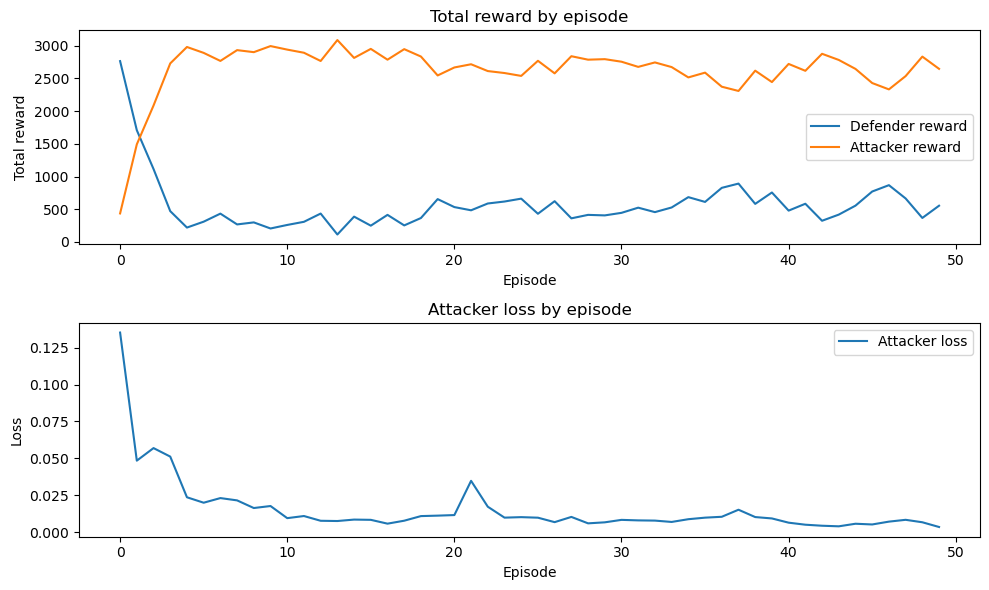

In [13]:
# ----------------------------
# Plot training curves
# ----------------------------
if not os.path.exists('results'):
    os.makedirs('results')

plt.figure(figsize=(10,6))
plt.subplot(211)
plt.plot(np.arange(len(def_reward_chain)), def_reward_chain, label='Defender reward')
plt.plot(np.arange(len(att_reward_chain)), att_reward_chain, label='Attacker reward')
plt.title('Total reward by episode')
plt.xlabel('Episode')
plt.ylabel('Total reward')
plt.legend()

plt.subplot(212)
plt.plot(np.arange(len(att_loss_chain)), att_loss_chain, label='Attacker loss')
plt.title('Attacker loss by episode')
plt.xlabel('Episode')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
#plt.savefig('results/train_adv_aci_iot_2023.png', dpi=300)
plt.show()


# Test and evaluation (ACI-IoT-2023)


In [14]:
from keras.models import model_from_json

import itertools
from sklearn.metrics import f1_score
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import  confusion_matrix
from imblearn.metrics import geometric_mean_score

In [15]:

def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    print(cm)

    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    fmt = '.2f' if normalize else 'd'
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')


In [16]:
# ----------------------------
# TEST (Defender DNN on ACI-IoT-2023 test split)
# ----------------------------
from keras.models import model_from_json
from sklearn.metrics import classification_report, confusion_matrix

formated_test_path = "formated_test_aci_iot_2023_adv.csv"
data_dir = "C:/Users/Curtis Rookard/OneDrive/Desktop/Research/Research Projects/Asymmetric_RL_Agents/datasets/aci/"

# Load defender model
defender_dnn = DefenderDNN.load("C:/Users/Curtis Rookard/OneDrive/Desktop/Research/Research Projects/Asymmetric_RL_Agents/models_aci_iot_2023/defender_dnn_model_aci_iot_2023.json", 
                                "C:/Users/Curtis Rookard/OneDrive/Desktop/Research/Research Projects/Asymmetric_RL_Agents/models_aci_iot_2023/defender_dnn_model_aci_iot_2023.weights.h5",  
                                learning_rate=1e-3)

# Define environment for test (must match the same formatted paths)
env_test = RLenv(
    'test',
    dataset='ACI-IoT-2023',
    data_dir=data_dir,
    formated_train_path="formated_train_aci_iot_2023_adv.csv",
    formated_test_path=formated_test_path,
    batch_size=32,
    iterations_episode=100,
    include_benign=True,      # optional, but avoids "empty after filtering" if your dir is benign-only
    force_reformat=True       # <-- rebuild formatted CSVs even if they exist
)

states, labels = env_test.get_batch(batch_size="full")   # states: features; labels: fine-label one-hot columns

print("states shape:", states.shape)
print("labels shape:", labels.shape)
print("first label columns:", list(labels.columns)[:10])

# True coarse labels (robust)
if labels.shape[0] == 0:
    raise ValueError(
        "Test split is empty (0 rows). Most common cause: your raw data contains only BENIGN rows "
        "(e.g., Monday) and include_benign=False filtered everything out. "
        "Fix: add Tue–Fri ACI-IoT-2023 CSVs to data_dir OR set include_benign=True and reformat."
    )

if labels.shape[1] == 0:
    raise ValueError(
        "No one-hot label columns were found (0 label columns). This usually means the formatted CSV was created "
        "with no remaining classes (often because include_benign=False removed all rows). "
        "Fix: point data_dir to data containing attacks OR set include_benign=True and reformat."
    )

fine_idx = np.argmax(labels.to_numpy(), axis=1)

# Use the actual one-hot column names as the fine label name
fine_labels = labels.columns.to_numpy()[fine_idx]

# Map fine label -> coarse type (fallback if needed)
coarse_labels = np.array([env_test.attack_map.get(lbl, _label_to_type(lbl)) for lbl in fine_labels])

y_true = np.array([env_test.attack_types.index(t) for t in coarse_labels], dtype=int)

# Predictions
y_pred = defender_dnn.act(states)

print("Attack types (classes):", env_test.attack_types)
print("\nClassification report:\n")
print(classification_report(y_true, y_pred, target_names=env_test.attack_types))

cm = confusion_matrix(y_true, y_pred)
print("\nConfusion matrix:\n", cm)


states shape: (246283, 75)
labels shape: (246283, 12)
first label columns: ['ARP Spoofing', 'Benign', 'DNS Flood', 'Dictionary Attack', 'ICMP Flood', 'OS Scan', 'Ping Sweep', 'Port Scan', 'SYN Flood', 'Slowloris']
Attack types (classes): ['Spoofing', 'BENIGN', 'DoS', 'BruteForce', 'Recon']

Classification report:

              precision    recall  f1-score   support

    Spoofing       0.00      0.00      0.00         1
      BENIGN       0.99      0.98      0.99     65859
         DoS       1.00      1.00      1.00     61092
  BruteForce       0.99      0.98      0.98      1276
       Recon       0.99      1.00      1.00    118055

    accuracy                           0.99    246283
   macro avg       0.79      0.79      0.79    246283
weighted avg       0.99      0.99      0.99    246283


Confusion matrix:
 [[     0      1      0      0      0]
 [     0  64678    215     16    950]
 [     0    162  60930      0      0]
 [     0     24      0   1252      0]
 [     0    196      0 

Confusion matrix, without normalization
[[     0      1      0      0      0]
 [     0  64678    215     16    950]
 [     0    162  60930      0      0]
 [     0     24      0   1252      0]
 [     0    196      0      0 117859]]


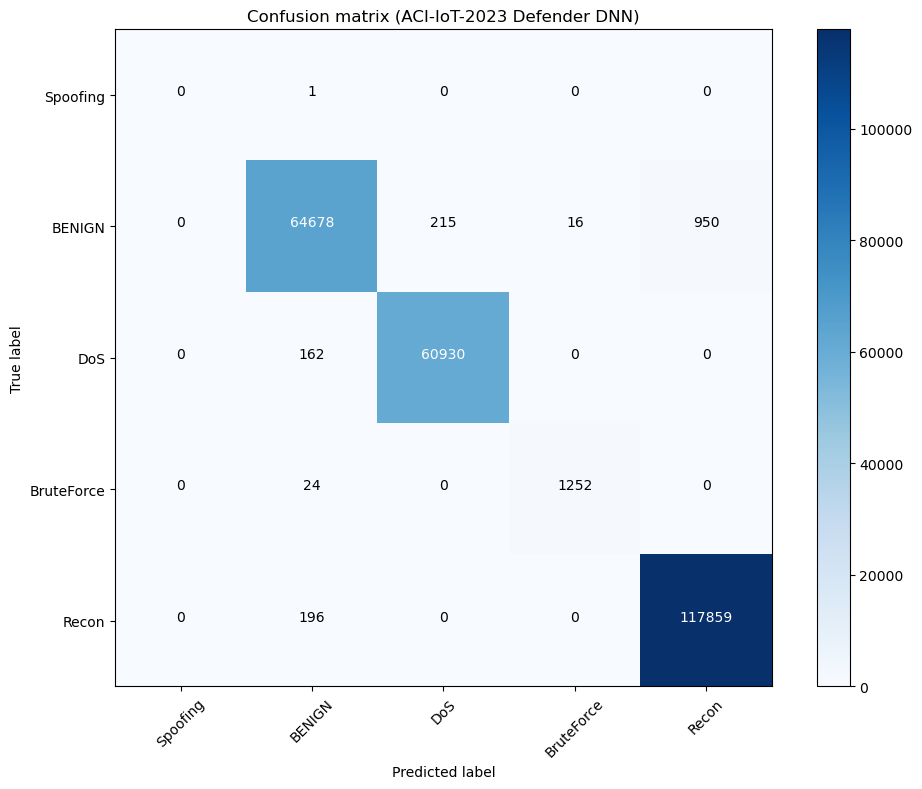

Normalized confusion matrix
[[0.00000000e+00 1.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00]
 [0.00000000e+00 9.82067751e-01 3.26455002e-03 2.42943258e-04
  1.44247559e-02]
 [0.00000000e+00 2.65173836e-03 9.97348262e-01 0.00000000e+00
  0.00000000e+00]
 [0.00000000e+00 1.88087774e-02 0.00000000e+00 9.81191223e-01
  0.00000000e+00]
 [0.00000000e+00 1.66024311e-03 0.00000000e+00 0.00000000e+00
  9.98339757e-01]]


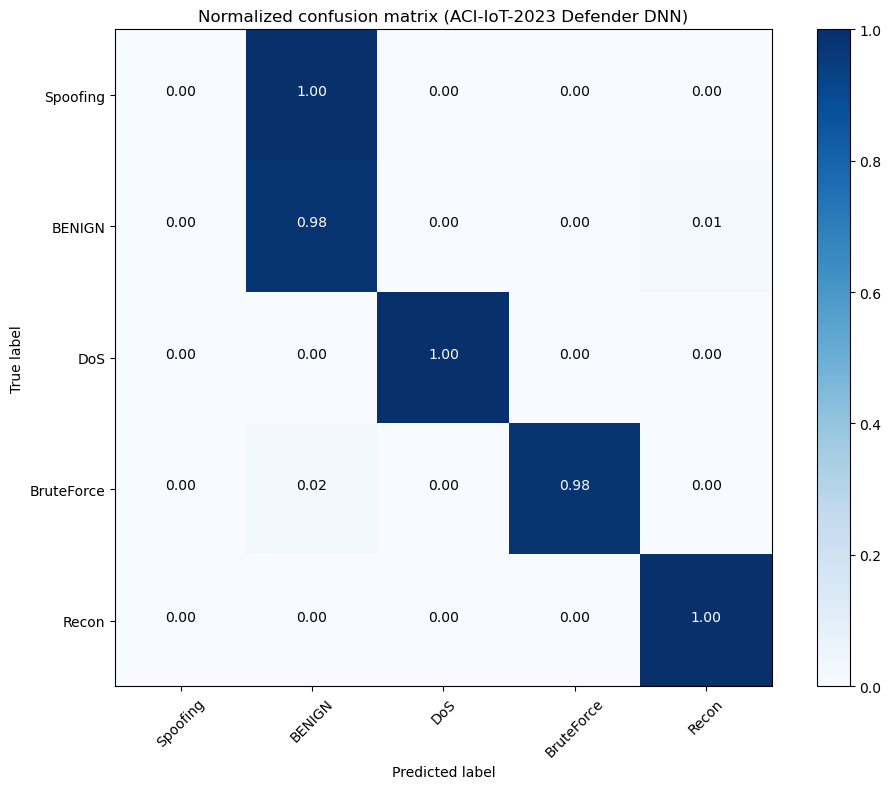

In [17]:
# Plot confusion matrix (normalized + raw)
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10,8))
plot_confusion_matrix(cm, classes=env_test.attack_types, normalize=False,
                      title='Confusion matrix (ACI-IoT-2023 Defender DNN)')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10,8))
plot_confusion_matrix(cm, classes=env_test.attack_types, normalize=True,
                      title='Normalized confusion matrix (ACI-IoT-2023 Defender DNN)')
plt.tight_layout()
plt.show()


In [18]:
# Summary metrics
acc = accuracy_score(y_true, y_pred)
prec_macro = precision_score(y_true, y_pred, average='macro', zero_division=0)
rec_macro = recall_score(y_true, y_pred, average='macro', zero_division=0)
f1_macro = f1_score(y_true, y_pred, average='macro', zero_division=0)
gmean_macro = geometric_mean_score(y_true, y_pred, average='macro')

print(f"Accuracy:          {acc:.4f}"        )
print(f"Precision (macro): {prec_macro:.4f}" )
print(f"Recall    (macro): {rec_macro:.4f}"  )
print(f"F1        (macro): {f1_macro:.4f}"   )
print(f"G-Mean    (macro): {gmean_macro:.4f}")


Accuracy:          0.9936
Precision (macro): 0.7940
Recall    (macro): 0.7918
F1        (macro): 0.7929
G-Mean    (macro): 0.8889


In [19]:
# # ----------------------------
# # 6) Explainability for the defender (SHAP + SAGE)
# # ----------------------------
# # SHAP (recommended): uses a small background set to keep runtime manageable
# try:
#     import shap

#     # background and evaluation samples
#     background = X_tr[np.random.choice(X_tr.shape[0], size=min(256, X_tr.shape[0]), replace=False)]
#     sample = X_val[:min(512, X_val.shape[0])]

#     explainer = shap.Explainer(defender_dnn.model, background)
#     shap_values = explainer(sample)

#     # Global importance (bar)
#     shap.plots.bar(shap_values, max_display=20)
#     # Local/summary (beeswarm)
#     shap.plots.beeswarm(shap_values, max_display=20)

# except Exception as e:
#     print(f"SHAP explainability skipped (install shap or check TF/Keras compatibility): {e}")


In [20]:
# # ----------------------------
# # 6) Explainability for the defender (SHAP + SAGE)
# # ----------------------------

# try:
#     import sage

#     # 1) Prediction fn must return probabilities (N, C)
#     def pred_fn(x):
#         x = np.asarray(x, dtype=np.float32)
#         return defender_dnn.model.predict(x, verbose=0)

#     # 2) Background data for the imputer (keep small for speed)
#     bg_idxs = np.random.choice(X_tr.shape[0], size=min(512, X_tr.shape[0]), replace=False)
#     X_bg = X_tr[bg_idxs]

#     # 3) Data to explain
#     ex_idxs = np.random.choice(X_tr.shape[0], size=min(2000, X_tr.shape[0]), replace=False)
#     X_sage = X_tr[ex_idxs]
#     y_sage = y_tr[ex_idxs]

#     # If y is one-hot, convert to class index
#     if y_sage.ndim > 1 and y_sage.shape[1] > 1:
#         y_sage = np.argmax(y_sage, axis=1)

#     # 4) Build imputer + estimator (THIS is the key change)
#     imputer = sage.MarginalImputer(pred_fn, X_bg)
#     estimator = sage.PermutationEstimator(imputer, loss="cross entropy")

#     # 5) Compute SAGE values
#     imps = estimator(X_sage, y_sage, n_permutations=64)

#     # 6) Plot
#     feature_names = list(X_train.columns)  # or your stored feature name list
#     imps.plot(feature_names, max_features=20, title="SAGE Plot for Defender DNN")
    
# except Exception as e:
#     print(f"SAGE explainability skipped: {e}")
